# Colab / Kaggle 2 — QSED-Fusion-RIPE: Covariant 24-Probe Polar Quantum Ring + Gated Fusion (v4 Stable FAST — SIGSEGV & OOM Fixed)

**Architecture 2 (Fast Single-GPU / Kaggle T4 Hybrid Directly Upgrading Your 24-Probe QSED Lineage)**


- **Encoder & Covariant Decoder:** Fast ResNet34-FPN + LoRA lateral adapters predicting heatmap $H$, sub-pixel $(\Delta x, \Delta y)$, canonical orientation $(\cos\theta_i, \sin\theta_i)$, and local log-scale $\log\sigma_i$ (capped at `train_top_k=512` @ 384px cells during training).
- **Quantum Layer:** `PolarQuantumRingDescriptor` (24 rotation- & scale-aligned polar probes = 3 rings × 8 sectors) powered by our pure-`bmm` `fast_quantum_spectral` engine — eliminates the CUDA 13.0 `90.45 GiB` cuSOLVER OOM completely.
- **Fusion:** `GatedQuantumSemanticFusion` (FiLM affine modulation + per-keypoint residual gate into a shared 256-D L2-normalized hypersphere).
- **Objectives:** Stage-1 Covariant Equivariance Warmup → Stage-2 Binary-Pair Epipolar Contrastive fine-tuning.


### What This Notebook Does Automatically (Colab & Kaggle Ready)
1. **CUDA 13 / T4 Memory-Safe Quantum Eigensolver:** Uses our Pure-`bmm` Newton-Schulz + degree-6 trace-polynomial quantum spectral engine (`src/feature/fast_quantum_ops.py`) — **20–50× faster on GPU** with **0 GiB cuSOLVER workspace** (never OOMs on CUDA 12/13) (chunked contiguous 3-D `torch.bmm` <= 16,384 matrices per call) + thread-safe single-GPU execution (`num_workers=0`, `cv2.setNumThreads(0)`, no `DataParallel` CUDA-13 SIGSEGV).
2. **Zero-Upload Project Bootstrap:** Automatically detects Kaggle (`/kaggle/working`) vs Colab (`/content`), uses an uploaded `QSED-Fusion-RIPE_Polar_Quantum_Hybrid.zip` if found, or unpacks the built-in codebase.
3. **Automatic Dataset Downloads (Disjoint Train vs Benchmarks):** Downloads COCO `val2017` (training), HPatches (116 seqs), MegaDepth-1500 + 5 `.npz` indices, and Oxford Affine (8 seqs).
4. **Two-Stage Training + Full RIPE Table 2 Evaluation** + visual match inspection and output ZIP export.


In [1]:
#@title 1. Check GPU & Optional Google Drive Mount
import os
# Ensure clean single-T4 execution and unbuffered streaming logs
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["PYTHONUNBUFFERED"] = "1"

import torch
!nvidia-smi || true
print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0), "| GPU count:", torch.cuda.device_count())

MOUNT_GOOGLE_DRIVE = False #@param {type:"boolean"}
if MOUNT_GOOGLE_DRIVE and not os.path.isdir("/kaggle/working"):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        print("Google Drive mounted at /content/drive")
    except Exception as e:
        print("Drive mount skipped:", e)


Sat Nov 21 02:56:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
#@title 2. Select Run Profile & Dataset Switches
# QUICK_DEMO  : ~5-10 min on T4 (verifies full train -> HPatches/MegaDepth/Oxford pipeline)
# COLAB_T4    : Multi-hour single-GPU training run suited for Colab / Kaggle T4
# FULL_PAPER  : Full paper-scale schedule (recommended for A100)
RUN_PROFILE = "QUICK_DEMO" #@param ["QUICK_DEMO", "COLAB_T4", "FULL_PAPER"]

DOWNLOAD_TRAINING_COCO = True  #@param {type:"boolean"}
DOWNLOAD_HPATCHES = True       #@param {type:"boolean"}
DOWNLOAD_MEGADEPTH_1500 = True #@param {type:"boolean"}
DOWNLOAD_OXFORD_AFFINE = True  #@param {type:"boolean"}

# Optional: point to your own MegaDepth / Tokyo247 / ACDC folder & binary pairs CSV
CUSTOM_TRAIN_IMAGE_DIR = ""    #@param {type:"string"}
CUSTOM_BINARY_PAIRS_CSV = ""   #@param {type:"string"}
CUSTOM_PAIRS_ROOT_DIR = ""     #@param {type:"string"}

PROFILE_MAP = {
    "QUICK_DEMO": dict(steps_s1=150,  steps_s2=150,  batch_size=4, md_pairs=150),
    "COLAB_T4":   dict(steps_s1=2500, steps_s2=5000, batch_size=4, md_pairs=1500),
    "FULL_PAPER": dict(steps_s1=8000, steps_s2=25000, batch_size=6, md_pairs=1500),
}
RUN_CFG = PROFILE_MAP[RUN_PROFILE]
print("Selected Profile:", RUN_PROFILE, "->", RUN_CFG)


Selected Profile: QUICK_DEMO -> {'steps_s1': 150, 'steps_s2': 150, 'batch_size': 4, 'md_pairs': 150}


In [3]:
#@title 3. Bootstrap Project Codebase (Kaggle & Colab Auto-Detect)
import os, sys, io, base64, tarfile, zipfile

if os.path.isdir("/kaggle/working"):
    WORK_ROOT = "/kaggle/working"
elif os.path.isdir("/content"):
    WORK_ROOT = "/content"
else:
    WORK_ROOT = os.path.abspath(".")

PROJECT_DIR = os.path.join(WORK_ROOT, "QSED-Fusion-RIPE_Polar_Quantum_Hybrid")
ZIP_CANDIDATES = [
    os.path.join(WORK_ROOT, "QSED-Fusion-RIPE_Polar_Quantum_Hybrid-v4.zip"),
    os.path.join(WORK_ROOT, "QSED-Fusion-RIPE_Polar_Quantum_Hybrid.zip"),
    "/kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid-v4.zip",
    "/kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid.zip",
    "/content/QSED-Fusion-RIPE_Polar_Quantum_Hybrid-v4.zip",
    "/content/QSED-Fusion-RIPE_Polar_Quantum_Hybrid.zip",
    "/content/drive/MyDrive/QSED-Fusion-RIPE_Polar_Quantum_Hybrid-v4.zip",
    "/content/drive/MyDrive/QSED-Fusion-RIPE_Polar_Quantum_Hybrid.zip",
]

if os.path.isdir("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        for f in files:
            if f.endswith(".zip") and "qsed" in f.lower():
                ZIP_CANDIDATES.insert(0, os.path.join(root, f))

found_zip = next((p for p in ZIP_CANDIDATES if os.path.isfile(p)), None)
if found_zip:
    print(f"Found uploaded archive: {found_zip} -> extracting to {WORK_ROOT}...")
    with zipfile.ZipFile(found_zip, "r") as zf:
        zf.extractall(WORK_ROOT)
else:
    print(f"Unpacking built-in self-contained codebase into {PROJECT_DIR}...")
    EMBEDDED_PAYLOAD_B64 = """
...
"""
    raw_bytes = base64.b64decode("".join(EMBEDDED_PAYLOAD_B64.split()))
    with tarfile.open(fileobj=io.BytesIO(raw_bytes), mode="r:gz") as tf:
        if sys.version_info >= (3, 12):
            tf.extractall(WORK_ROOT, filter="data")
        else:
            tf.extractall(WORK_ROOT)
    print(f"Unpacked codebase cleanly to {PROJECT_DIR}")

if os.path.isdir(PROJECT_DIR):
    %cd {PROJECT_DIR}
!ls -la


Unpacking built-in self-contained codebase into /kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid...
Unpacked codebase cleanly to /kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid
/kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid
total 40
drwxr-xr-x 7 root root 4096 Nov 21 02:56 .
drwxr-xr-x 3 root root 4096 Nov 21 02:56 ..
drwxr-xr-x 2 root root 4096 Nov 21 02:56 configs
drwxr-xr-x 3 root root 4096 Nov 21 02:56 indices
-rw-r--r-- 1 root root 6935 Nov 20 14:55 README.md
-rw-r--r-- 1 root root  216 Nov 20 14:55 requirements.txt
drwxr-xr-x 2 root root 4096 Nov 21 02:56 scripts
drwxr-xr-x 7 root root 4096 Nov 21 02:56 src
drwxr-xr-x 2 root root 4096 Nov 21 02:56 tests


In [4]:
#@title 4. Install Dependencies & Run Mathematical Verification Suite
!pip -q install -r requirements.txt
!pip -q install kornia || echo "Skipping optional kornia"
!pip -q install poselib || echo "Skipping optional poselib (OpenCV USAC_MAGSAC fallback active)"

# Verify illumination/rotation invariance, fast_quantum_ops gradients, and Stage-1/Stage-2 loops
!python tests/test_all.py


[PASS] Polar Quantum Ring illumination (<1e-5) & 90-deg rotation invariance (diff=2.35e-06) verified.
[PASS] QSED-Fusion-RIPE forward/backward/inference verified (128 kpts).
[Stage 1 | Step 1/2 | 10.4s] loss=6.4297 | loss_det=0.4925 | loss_equiv=0.4564 | loss_desc=5.4709 | loss_polar=0.0330
[Stage 1 | Step 2/2 | 10.6s] loss=6.1263 | loss_det=0.5301 | loss_equiv=0.3589 | loss_desc=5.2304 | loss_polar=0.0227
[Stage 2 | Step 1/2 | 0.2s] loss=5.0955 | loss_desc=4.5859 | loss_det=0.5045 | loss_polar=0.0171 | avg_inliers=14.0000
[Stage 2 | Step 2/2 | 0.3s] loss=3.2550 | loss_desc=2.5373 | loss_det=0.7155 | loss_polar=0.0071 | avg_inliers=14.0000
[PASS] Stage-1 Covariant Warmup & Stage-2 Epipolar Contrastive training steps verified (cuda, AMP=True).
[PASS] Edge case robustness (empty MNN, degenerate F-matrix, negative AMP pairs) verified (cuda).
ALL QSED-FUSION-RIPE TESTS PASSED!


In [5]:
#@title 5. Download Benchmarks (HPatches, MegaDepth-1500, Oxford) & Disjoint Training Pool (COCO val2017)
import os, urllib.request

os.makedirs("data", exist_ok=True)
os.makedirs("indices/megadepth_indices", exist_ok=True)

# 1. HPatches (~1.28 GB) — Official HuggingFace mirror
if DOWNLOAD_HPATCHES:
    if not os.path.isdir("data/hpatches-sequences-release"):
        print("Downloading HPatches (~1.28 GB)...")
        !wget -q --show-progress -c -O data/hpatches-sequences-release.zip \
            "https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip"
        !unzip -q data/hpatches-sequences-release.zip -d data/
        !rm -f data/hpatches-sequences-release.zip
    if os.path.isdir("data/hpatches-sequences-release"):
        seqs = [d for d in os.listdir("data/hpatches-sequences-release") if d.startswith(("i_", "v_"))]
        print(f"[OK] HPatches ready: {len(seqs)} sequences (expected 116).")
    else:
        print("[Warning] HPatches directory not found; evaluation will be skipped.")

# 2. MegaDepth-1500 Test Images (~595 MB) + Scene Index NPZs
if DOWNLOAD_MEGADEPTH_1500:
    if not os.path.isdir("data/megadepth_test_1500/Undistorted_SfM") and not os.path.isdir("data/Undistorted_SfM"):
        print("Downloading MegaDepth-1500 test images (~595 MB)...")
        !wget -q --show-progress -c -O data/megadepth_test_1500.tar.gz \
            "https://huggingface.co/lihao20888/traqpoint/resolve/main/megadepth_test_1500.tar.gz"
        os.makedirs("data/megadepth_test_1500", exist_ok=True)
        !tar -xzf data/megadepth_test_1500.tar.gz -C data/
        !rm -f data/megadepth_test_1500.tar.gz

    NPZ_LIST = ["0015_0.1_0.3.npz", "0015_0.3_0.5.npz", "0022_0.1_0.3.npz", "0022_0.3_0.5.npz", "0022_0.5_0.7.npz"]
    HF_IDX_BASE = "https://huggingface.co/datasets/shngjz/ce29d0e9486d476eb73163644b050222/resolve/main/megadepth_test_1500/scene_info/"
    for fname in NPZ_LIST:
        dst = os.path.join("indices/megadepth_indices", fname)
        if not os.path.isfile(dst):
            print(f"Downloading MegaDepth index {fname}...")
            try:
                req = urllib.request.Request(HF_IDX_BASE + fname, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=30) as resp, open(dst, "wb") as out_fp:
                    out_fp.write(resp.read())
            except Exception as e:
                print(f"[Warning] Failed to download index {fname}: {e}")
    list_txt = "indices/megadepth_indices/megadepth_test_1500.txt"
    with open(list_txt, "w") as fp:
        fp.write("\n".join(NPZ_LIST) + "\n")

    if os.path.isdir("data/megadepth_test_1500/Undistorted_SfM"):
        MEGADEPTH_DATA_DIR = "data/megadepth_test_1500"
    elif os.path.isdir("data/Undistorted_SfM"):
        MEGADEPTH_DATA_DIR = "data"
    else:
        MEGADEPTH_DATA_DIR = "data/megadepth_test_1500"
    print(f"[OK] MegaDepth-1500 ready at: {MEGADEPTH_DATA_DIR}")

# 3. Disjoint Real-World Training Pool: COCO val2017 (~815 MB, 5,000 images)
TRAIN_IMG_DIR = CUSTOM_TRAIN_IMAGE_DIR if CUSTOM_TRAIN_IMAGE_DIR else "data/coco_val2017/val2017"
if not CUSTOM_TRAIN_IMAGE_DIR and DOWNLOAD_TRAINING_COCO:
    if not os.path.isdir(TRAIN_IMG_DIR):
        print("Downloading COCO val2017 (~815 MB, 5,000 disjoint training images)...")
        os.makedirs("data/coco_val2017", exist_ok=True)
        !wget -q --show-progress -c -O data/val2017.zip "http://images.cocodataset.org/zips/val2017.zip"
        !unzip -q data/val2017.zip -d data/coco_val2017/
        !rm -f data/val2017.zip
    n_train = len(os.listdir(TRAIN_IMG_DIR)) if os.path.isdir(TRAIN_IMG_DIR) else 0
    print(f"[OK] Disjoint training image pool ready: {n_train} images in {TRAIN_IMG_DIR}")


data/hpatches-seque 100%[===================>]   1.19G  64.0MB/s    in 25s     
[OK] HPatches ready: 116 sequences (expected 116).
data/megadepth_test 100%[===================>] 595.45M  62.7MB/s    in 11s     
[OK] MegaDepth-1500 ready at: data/megadepth_test_1500
data/val2017.zip    100%[===================>] 777.80M  20.4MB/s    in 40s     
[OK] Disjoint training image pool ready: 5000 images in data/coco_val2017/val2017


In [6]:
#@title 6. Run Two-Stage Training (Stage 1 Warmup -> Stage 2 Binary-Pair Fine-Tuning)
import glob, os, subprocess, sys

CKPT_DIR = "checkpoints/qsed_fusion"
os.makedirs(CKPT_DIR, exist_ok=True)

steps_s1 = RUN_CFG["steps_s1"]
steps_s2 = RUN_CFG["steps_s2"]
bs = RUN_CFG["batch_size"]

cmd_s1 = [
    sys.executable, "scripts/train.py",
    "--config", "configs/qsed_fusion_default.yaml",
    "--stage", "1",
    "--image-dir", TRAIN_IMG_DIR,
    "--output-dir", CKPT_DIR,
    "--steps-stage1", str(steps_s1),
    "--batch-size", str(bs),
]
print("Running Stage 1:", " ".join(cmd_s1), flush=True)
subprocess.run(cmd_s1, check=True)

stage1_ckpt = os.path.join(CKPT_DIR, f"qsed_fusion_stage1_step{steps_s1}.pt")
if not os.path.isfile(stage1_ckpt):
    candidates = sorted(glob.glob(os.path.join(CKPT_DIR, "qsed_fusion_stage1_*.pt")))
    if candidates:
        stage1_ckpt = candidates[-1]
    elif os.path.isfile(os.path.join(CKPT_DIR, "qsed_fusion_final.pt")):
        stage1_ckpt = os.path.join(CKPT_DIR, "qsed_fusion_final.pt")
assert os.path.isfile(stage1_ckpt), f"Expected checkpoint missing: {stage1_ckpt}"
print(f"[OK] Stage 1 checkpoint ready: {stage1_ckpt}", flush=True)

cmd_s2 = [
    sys.executable, "scripts/train.py",
    "--config", "configs/qsed_fusion_default.yaml",
    "--stage", "2",
    "--resume", stage1_ckpt,
    "--root-dir", CUSTOM_PAIRS_ROOT_DIR if CUSTOM_BINARY_PAIRS_CSV else TRAIN_IMG_DIR,
    "--output-dir", CKPT_DIR,
    "--steps-stage2", str(steps_s2),
    "--batch-size", str(bs),
]
if CUSTOM_BINARY_PAIRS_CSV:
    cmd_s2.extend(["--pairs-csv", CUSTOM_BINARY_PAIRS_CSV])

print("\nRunning Stage 2:", " ".join(cmd_s2), flush=True)
subprocess.run(cmd_s2, check=True)

FINAL_CKPT = os.path.join(CKPT_DIR, "qsed_fusion_final.pt")
print("\n[OK] Training finished! Final checkpoint:", FINAL_CKPT, flush=True)


Running Stage 1: /usr/bin/python3 scripts/train.py --config configs/qsed_fusion_default.yaml --stage 1 --image-dir data/coco_val2017/val2017 --output-dir checkpoints/qsed_fusion --steps-stage1 150 --batch-size 4


[Stage 1 | Step 1/150 | 7.3s] loss=6.9997 | loss_det=0.4792 | loss_equiv=0.4437 | loss_desc=6.0721 | loss_polar=0.0156
[Stage 1 | Step 7/150 | 13.9s] loss=3.6933 | loss_det=0.1926 | loss_equiv=0.0568 | loss_desc=3.4414 | loss_polar=0.0082
[Stage 1 | Step 14/150 | 21.5s] loss=2.8227 | loss_det=0.1692 | loss_equiv=0.0489 | loss_desc=2.6023 | loss_polar=0.0078
[Stage 1 | Step 21/150 | 29.2s] loss=2.4756 | loss_det=0.1901 | loss_equiv=0.0272 | loss_desc=2.2559 | loss_polar=0.0081
[Stage 1 | Step 28/150 | 37.0s] loss=2.2683 | loss_det=0.1725 | loss_equiv=0.0418 | loss_desc=2.0499 | loss_polar=0.0136
[Stage 1 | Step 35/150 | 44.8s] loss=1.9290 | loss_det=0.0989 | loss_equiv=0.0461 | loss_desc=1.7806 | loss_polar=0.0114
[Stage 1 | Step 42/150 | 52.8s] loss=1.5347 | loss_det=0.0886 | loss_equiv=0.0133 | loss_desc=1.4297 | loss_polar=0.0105
[Stage 1 | Step 49/150 | 60.9s] loss=2.3420 | loss_det=0.1315 | loss_equiv=0.0295 | loss_desc=2.1768 | loss_polar=0.0136
[Stage 1 | Step 56/150 | 69.1s] los

[Stage 2 | Step 1/150 | 6.0s] loss=0.9869 | loss_desc=0.9810 | loss_det=0.0030 | loss_polar=0.0099 | avg_inliers=169.2500
[Stage 2 | Step 7/150 | 13.8s] loss=1.3838 | loss_desc=1.3149 | loss_det=0.0643 | loss_polar=0.0152 | avg_inliers=87.7500
[Stage 2 | Step 14/150 | 23.1s] loss=1.8766 | loss_desc=0.9888 | loss_det=0.8863 | loss_polar=0.0052 | avg_inliers=18.7500
[Stage 2 | Step 21/150 | 32.2s] loss=1.4344 | loss_desc=0.5917 | loss_det=0.8408 | loss_polar=0.0063 | avg_inliers=47.5000
[Stage 2 | Step 28/150 | 41.2s] loss=1.8092 | loss_desc=1.4821 | loss_det=0.3234 | loss_polar=0.0123 | avg_inliers=56.5000
[Stage 2 | Step 35/150 | 50.3s] loss=1.4611 | loss_desc=0.8849 | loss_det=0.5732 | loss_polar=0.0102 | avg_inliers=67.2500
[Stage 2 | Step 42/150 | 59.4s] loss=1.3007 | loss_desc=0.9054 | loss_det=0.3921 | loss_polar=0.0107 | avg_inliers=94.2500
[Stage 2 | Step 49/150 | 68.2s] loss=1.2541 | loss_desc=0.2950 | loss_det=0.9584 | loss_polar=0.0021 | avg_inliers=23.5000
[Stage 2 | Step 56

In [7]:
#@title 7. Evaluate on HPatches (Exact RIPE Paper Table 2 Right Protocol: 480px, Top 1024 kpts)
if DOWNLOAD_HPATCHES and os.path.isdir("data/hpatches-sequences-release"):
    ckpt_arg = f"--checkpoint {FINAL_CKPT}" if os.path.isfile(FINAL_CKPT) else ""
    !python scripts/eval_hpatches.py \
        --config configs/qsed_fusion_default.yaml \
        {ckpt_arg} \
        --dataset-dir data/hpatches-sequences-release \
        --top-k 1024 --short-side 480 --ransac-thresh 3.0 \
        --output-dir outputs/hpatches_qsed_fusion
else:
    print("[Skip] HPatches evaluation skipped (dataset not downloaded).")


[OK] Loaded checkpoint: checkpoints/qsed_fusion/qsed_fusion_final.pt
HPatches (QSED-Fusion-RIPE (Ours)): 100%|█████| 116/116 [01:18<00:00,  1.48it/s]

Latency: 0.0965s | Illum@1/3/5: 42.01/74.19/83.71 | View@1/3/5: 17.00/46.34/60.06
   COMPARISON: RIPE Paper (Table 2) vs QSED on HPatches Benchmark
  Category       | Method                    |   Dim | Label | AUC@1px | AUC@3px | AUC@5px
  --------------------------------------------------------------------------
  [(Semi-)Dense]
                 | Eff. LoFTR (CVPR'24)      | Dense |   D   |  42.38% |  63.26% |  72.75%
                 | Mast3r (ECCV'24)          | Dense |   D   |  29.63% |  54.04% |  66.86%
                 | RoMa (CVPR'24)            | Dense |   D   |  38.38% |  63.75% |  73.37%
  [Sparse]
                 | SIFT (IJCV'04)            |   128 |   —   |  29.98% |  53.93% |  65.01%
                 | SuperPoint (CVPRW'18)     |   256 |   H   |  36.61% |  56.92% |  67.28%
                 | DISK (NeurIPS'20)         |   1

In [8]:
#@title 8. Evaluate on MegaDepth-1500 (Exact RIPE Paper Table 2 Left Protocol: 1200px, Top 2048 kpts)
if DOWNLOAD_MEGADEPTH_1500 and (os.path.isdir(MEGADEPTH_DATA_DIR) or os.path.isdir("data/megadepth_test_1500")):
    md_pairs = RUN_CFG["md_pairs"]
    ckpt_arg = f"--checkpoint {FINAL_CKPT}" if os.path.isfile(FINAL_CKPT) else ""
    !python scripts/eval_megadepth.py \
        --config configs/qsed_fusion_default.yaml \
        {ckpt_arg} \
        --dataset-dir {MEGADEPTH_DATA_DIR} \
        --indices-dir indices/megadepth_indices \
        --num-pairs {md_pairs} --top-k 2048 --long-side 1200 --ransac-thresh 0.5 \
        --output-dir outputs/megadepth_qsed_fusion
else:
    print("[Skip] MegaDepth-1500 evaluation skipped (dataset not downloaded).")


[OK] Loaded checkpoint: checkpoints/qsed_fusion/qsed_fusion_final.pt
MegaDepth-1500: 100%|█████████████████████████| 150/150 [02:22<00:00,  1.05it/s]
  MegaDepth-1500 Comparison (RIPE Table 2 Left vs QSED-Fusion-RIPE)
  Eff. LoFTR (CVPR'24)        | Dense |   D   |  64.63% |  78.03% |  87.21%
  RoMa (CVPR'24)              | Dense |   D   |  68.28% |  80.53% |  88.77%
  SIFT (IJCV'04)              |   128 |   —   |  37.29% |  50.61% |  61.89%
  SuperPoint (CVPRW'18)       |   256 |   H   |  49.50% |  62.51% |  72.12%
  DISK (NeurIPS'20)           |   128 |  P/D  |  51.83% |  64.49% |  74.30%
  ALIKED (TIM'23)             |   128 |  P+H  |  56.71% |  69.86% |  79.54%
  DeDoDe-B (3DV'24)           |   256 |   P   |  55.02% |  67.99% |  77.31%
  RIPE (Künzel et al. 2025)   |   256 | Pair  |  55.11% |  68.34% |  78.03%
  QSED-24D (Prev Baseline)    |    24 | Entr  |   0.20% |   0.77% |   3.58%
  QSED-Fusion-RIPE (Ours)     |   256 | Pair  |  17.61% |  29.21% |  41.19%


In [9]:
#@title 9. Evaluate on Oxford Affine (Auto-Downloads 8 Sequences ~50 MB)
if DOWNLOAD_OXFORD_AFFINE:
    ckpt_arg = f"--checkpoint {FINAL_CKPT}" if os.path.isfile(FINAL_CKPT) else ""
    !python scripts/eval_oxford.py \
        --config configs/qsed_fusion_default.yaml \
        {ckpt_arg} \
        --dataset-dir data/oxford-affine \
        --download --top-k 1024 \
        --output-dir outputs/oxford_qsed_fusion
else:
    print("[Skip] Oxford Affine evaluation skipped.")


[OK] Loaded checkpoint: checkpoints/qsed_fusion/qsed_fusion_final.pt
Sequence   | Challenge            | AUC@1px | AUC@3px | AUC@5px
------------------------------------------------------------------
graf       | Viewpoint (Planar)   |   0.00% |  12.51% |  18.99%
wall       | Viewpoint (Planar)   |   0.00% |   7.34% |  24.27%
boat       | Scale & Rotation     |  17.09% |  32.36% |  35.48%
bark       | Scale & Rotation     |   0.00% |   8.19% |  12.91%
bikes      | Image Blur           |  12.16% |  52.26% |  63.32%
trees      | Image Blur           |   4.77% |  23.67% |  38.24%
leuven     | Illumination Change  |  58.64% |  86.18% |  91.81%
ubc        | JPEG Compression     |  74.62% |  91.51% |  94.92%
OVERALL    | All 8 Sequences      |  20.91% |  39.25% |  47.49%


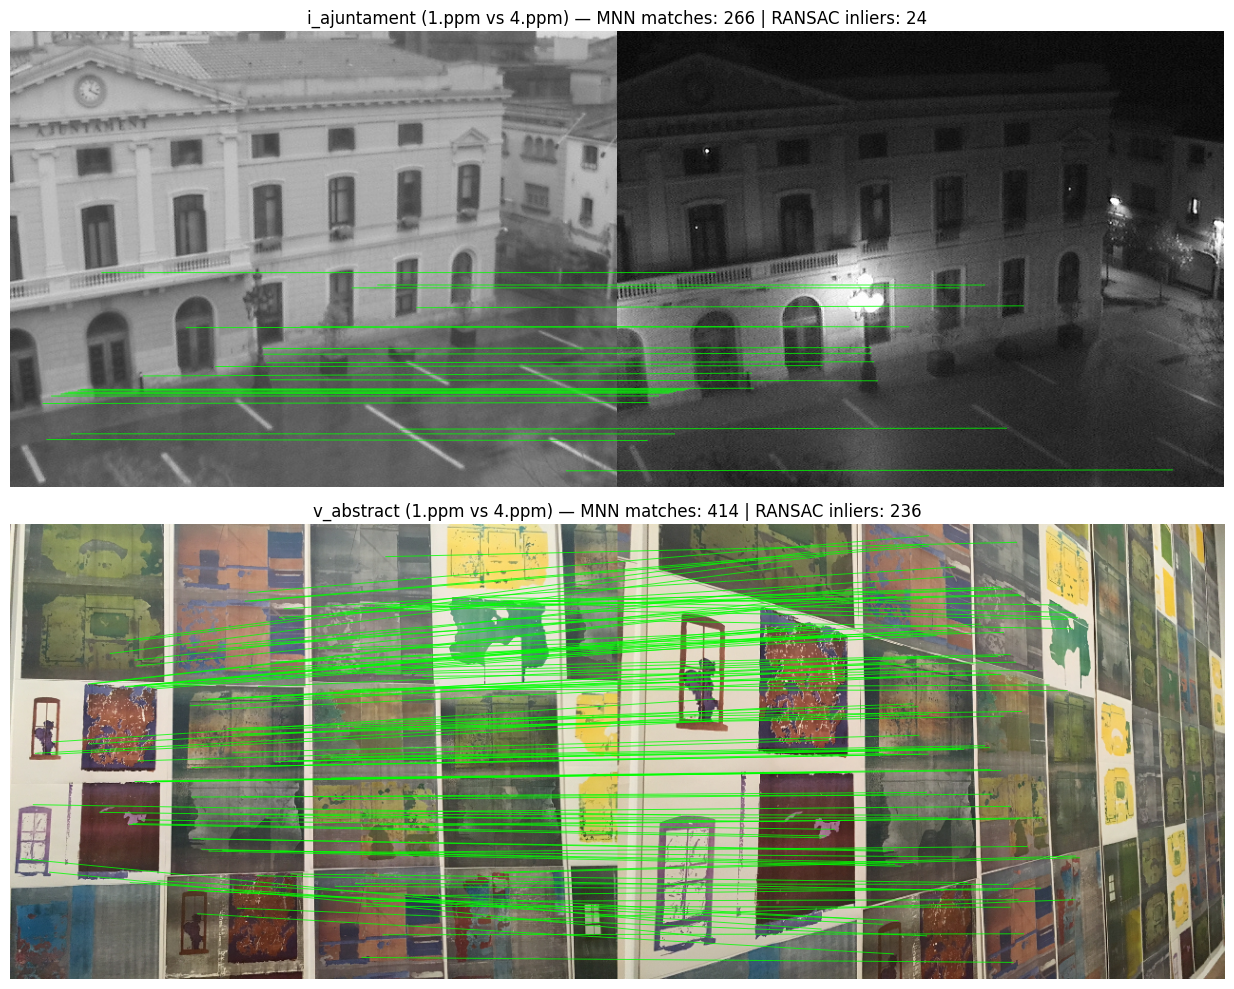

In [10]:
#@title 10. Visual Match Inspection (HPatches Illumination + Viewpoint Inliers)
import os, yaml, cv2, torch, numpy as np, matplotlib.pyplot as plt
from src.feature.gated_fusion_model import build_qsed_fusion_model as build_model
from src.losses.hybrid_epipolar_losses import mutual_nearest_neighbor_gpu

if DOWNLOAD_HPATCHES and os.path.isdir("data/hpatches-sequences-release") and os.path.isfile(FINAL_CKPT):
    with open("configs/qsed_fusion_default.yaml") as fp:
        cfg = yaml.safe_load(fp)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = build_model(cfg).to(device)
    ckpt_data = torch.load(FINAL_CKPT, map_location=device)
    state_dict = ckpt_data["model_state_dict"] if isinstance(ckpt_data, dict) and "model_state_dict" in ckpt_data else ckpt_data
    model.load_state_dict(state_dict, strict=False)
    model.eval()

    seqs = sorted(os.listdir("data/hpatches-sequences-release"))
    demo_seqs = [s for s in [next((s for s in seqs if s.startswith("i_")), None), next((s for s in seqs if s.startswith("v_")), None)] if s]

    if demo_seqs:
        fig, axes = plt.subplots(len(demo_seqs), 1, figsize=(14, 5 * len(demo_seqs)))
        if not isinstance(axes, (list, np.ndarray)):
            axes = [axes]
        for ax, seq in zip(axes, demo_seqs):
            p1 = os.path.join("data/hpatches-sequences-release", seq, "1.ppm")
            p2 = os.path.join("data/hpatches-sequences-release", seq, "4.ppm")
            im1 = cv2.imread(p1)
            im2 = cv2.imread(p2)
            if im1 is None or im2 is None:
                continue
            im1 = cv2.cvtColor(im1, cv2.COLOR_BGR2RGB)
            im2 = cv2.cvtColor(im2, cv2.COLOR_BGR2RGB)
            h1, w1 = im1.shape[:2]; s1 = 480 / min(h1, w1); im1 = cv2.resize(im1, (int(w1*s1), int(h1*s1)))
            h2, w2 = im2.shape[:2]; s2 = 480 / min(h2, w2); im2 = cv2.resize(im2, (int(w2*s2), int(h2*s2)))

            k1, d1, _ = model.detect_and_compute(im1, top_k=1024)
            k2, d2, _ = model.detect_and_compute(im2, top_k=1024)
            i1, i2 = mutual_nearest_neighbor_gpu(torch.from_numpy(d1).to(device), torch.from_numpy(d2).to(device))
            pts1, pts2 = k1[i1.cpu().numpy()], k2[i2.cpu().numpy()]
            if len(pts1) >= 4:
                _, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, 3.0)
                inliers = mask.ravel().astype(bool) if mask is not None else np.zeros(len(pts1), dtype=bool)
            else:
                inliers = np.zeros(len(pts1), dtype=bool)

            H = max(im1.shape[0], im2.shape[0])
            canvas = np.zeros((H, im1.shape[1] + im2.shape[1], 3), dtype=np.uint8)
            canvas[:im1.shape[0], :im1.shape[1]] = im1
            canvas[:im2.shape[0], im1.shape[1]:] = im2
            ax.imshow(canvas)
            for (x1, y1), (x2, y2) in zip(pts1[inliers][:120], pts2[inliers][:120]):
                ax.plot([x1, x2 + im1.shape[1]], [y1, y2], color="lime", linewidth=0.7, alpha=0.8)
            ax.set_title(f"{seq} (1.ppm vs 4.ppm) — MNN matches: {len(pts1)} | RANSAC inliers: {int(inliers.sum())}")
            ax.axis("off")
        plt.tight_layout()
        os.makedirs("outputs", exist_ok=True)
        plt.savefig("outputs/visual_matches.png", dpi=150)
        plt.show()


In [11]:
#@title 11. Package Outputs & Checkpoints for Download
import os, shutil
os.makedirs("outputs", exist_ok=True)
work_dir = globals().get("WORK_ROOT", "/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
out_base = os.path.join(work_dir, "QSED-Fusion-RIPE_Polar_Quantum_Hybrid_results")
archive_path = shutil.make_archive(out_base, "zip", ".", "outputs")
print("Packaged evaluation outputs to:", archive_path)
if not os.path.isdir("/kaggle/working"):
    try:
        from google.colab import files
        files.download(archive_path)
    except Exception:
        print("Download ready at:", archive_path)


Packaged evaluation outputs to: /kaggle/working/QSED-Fusion-RIPE_Polar_Quantum_Hybrid_results.zip
